# Additive vs MULTI-evolve comparison — APEX (A134P-free)

Compare additive (RidgeCV) predictions against MULTI-evolve 2-layer NN
predictions across the (−)A134P combinatorial mutation space
(15-mutation pool, 5–9 substitutions per variant).


In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

In [2]:
effect_dictionary = {}

full_df = pd.read_excel('../data/Table S14 APEX variants.xlsx')
full_df = full_df[[x for x in full_df.columns.values if 'Unnamed' not in x]]
# Transform both timepoints into log2 space
for timepoint in [10, 75]:
    full_df[f'logfc_{timepoint}min'] = full_df[f'Fold Improvement ({timepoint} min)'].apply(np.log2)
full_df

,Mutant,Fold Improvement (75 min),Fold Improvement (10 min),Origin,Variant ID,Legend,logfc_10min,logfc_75min
0,WT,1.000,1.000,NaN,NaN,WT = wild-type sequence,0.000000,0.000000
1,T192K,2.637,2.659,PLM zeroshot,NaN,Mutations are formatted as {original amino aci...,1.410884,1.398898
2,A167R,2.277,1.819,PLM zeroshot,NaN,NaN,0.863146,1.187134
3,N72A,2.157,3.340,PLM zeroshot,NaN,NaN,1.739848,1.109026
4,D222E,1.843,1.347,PLM zeroshot,NaN,NaN,0.429750,0.882056
...,...,...,...,...,...,...,...,...
309,K147T,0.507,NaN,EVOLVEpro Round 5,NaN,NaN,NaN,-0.979942
310,P219C,1.113,NaN,EVOLVEpro Round 5,NaN,NaN,NaN,0.154454
311,E29S,0.963,NaN,EVOLVEpro Round 5,NaN,NaN,NaN,-0.054392
312,D75A,0.250,NaN,EVOLVEpro Round 5,NaN,NaN,NaN,-2.000000


In [3]:
# Process the single amino acid data
# subset to the single amino acid data
singles = full_df[full_df['Origin'] == 'PLM zeroshot'].copy()
# make a dictionary mapping single amino-acid mutants to measured activity
for timepoint in [10, 75]:
    effect_dictionary[f'single_effect_{timepoint}'] = dict(zip(singles['Mutant'], singles[f'logfc_{timepoint}min']))

In [4]:
# Process the double mutants
# subset to the double amino acid data
doubles = full_df[full_df['Origin'] == 'Double Mutant'].copy()
# make a new column that is a list of the single amino acid changes that make up the double
doubles['muts'] = doubles['Mutant'].apply(lambda x: x.split('/'))
for timepoint in [10, 75]:
    doubles[f'single_prediction_{timepoint}'] = doubles['muts'].apply(lambda x: sum([effect_dictionary[f'single_effect_{timepoint}'][i] for i in x]))
    doubles[f'epistatic_effect_{timepoint}'] = doubles[f'logfc_{timepoint}min'] - doubles[f'single_prediction_{timepoint}']
    effect_dictionary[f'epistatic_effect_{timepoint}'] = dict(zip(doubles['Mutant'], doubles[f'epistatic_effect_{timepoint}']))
doubles

,Mutant,Fold Improvement (75 min),Fold Improvement (10 min),Origin,Variant ID,Legend,logfc_10min,logfc_75min,muts,single_prediction_10,epistatic_effect_10,single_prediction_75,epistatic_effect_75
83,A167R/T192V,5.003000,8.106118,Double Mutant,NaN,NaN,3.019011,2.322793,"[A167R, T192V]",2.600214,0.418797,2.405606,-0.082812
84,A167R/T192K,7.267000,12.549471,Double Mutant,NaN,NaN,3.649555,2.861360,"[A167R, T192K]",2.274029,1.375525,2.586032,0.275328
85,N72A/T192V,4.300000,7.379569,Double Mutant,NaN,NaN,2.883537,2.104337,"[N72A, T192V]",3.476916,-0.593380,2.327497,-0.223161
86,N72A/T192K,6.273000,11.074358,Double Mutant,NaN,NaN,3.469151,2.649156,"[N72A, T192K]",3.150732,0.318419,2.507924,0.141232
87,N72A/A167R,4.723000,8.320279,Double Mutant,NaN,NaN,3.056632,2.239704,"[N72A, A167R]",2.602994,0.453638,2.296160,-0.056457
...,...,...,...,...,...,...,...,...,...,...,...,...,...
197,K61R/A134P,22.634699,54.231523,Double Mutant,NaN,NaN,5.761060,4.500464,"[K61R, A134P]",6.297412,-0.536352,5.190615,-0.690151
198,A134P/S138A,24.259229,61.847639,Double Mutant,NaN,NaN,5.950647,4.600462,"[A134P, S138A]",7.279313,-1.328667,5.222418,-0.621956
199,N72A/A134P,23.237114,55.882667,Double Mutant,NaN,NaN,5.804329,4.538359,"[N72A, A134P]",7.467769,-1.663440,5.568458,-1.030099
200,A134P/D229A,22.186902,53.185015,Double Mutant,NaN,NaN,5.732948,4.471636,"[A134P, D229A]",7.316245,-1.583297,5.250204,-0.778567


In [5]:
# MULTI-evolve variants from the paper (used to define 'targets')
df = full_df[full_df['Origin'] == 'MULTI-evolve variant'].copy()
df['muts'] = df['Mutant'].apply(lambda x: x.split('/'))


In [6]:
# 15-mutation pool for the (−)A134P campaign
single_muts = [x.split('/') for x in doubles['Mutant'].unique()]
single_muts = list(set([item for sublist in single_muts for item in sublist]))
single_muts = [m for m in single_muts if m != 'A134P']
all_muts = []
for i in [5, 6, 7, 8, 9]:
    all_muts.append(pd.DataFrame({'muts': list(combinations(single_muts, i))}).assign(label=f'muts_{i}'))
all_muts = pd.concat(all_muts)
all_muts


,muts,label
0,"(A167R, N72A, K61R, D229A, E87Q)",muts_5
1,"(A167R, N72A, K61R, D229A, G50R)",muts_5
2,"(A167R, N72A, K61R, D229A, L80M)",muts_5
3,"(A167R, N72A, K61R, D229A, L84V)",muts_5
4,"(A167R, N72A, K61R, D229A, T192V)",muts_5
...,...,...
5000,"(G50R, L80M, L84V, T192V, I185V, T192K, S196A,...",muts_9
5001,"(G50R, L80M, L84V, D222E, I185V, T192K, S196A,...",muts_9
5002,"(G50R, L80M, T192V, D222E, I185V, T192K, S196A...",muts_9
5003,"(G50R, L84V, T192V, D222E, I185V, T192K, S196A...",muts_9


In [7]:
# remove mutants with multiple subs at one site (impossible)
all_muts['sites'] = all_muts['muts'].apply(lambda x: [int(i[1:-1]) for i in x])
mask = all_muts['sites'].apply(lambda x: len(x) == len(set(x)))
all_muts = all_muts[mask].copy()

In [8]:
# make all of the sub-doubles
all_muts['double_muts'] = all_muts['muts'].apply(lambda x: ["/".join(i) for i in list(combinations(x, 2))])
all_muts

,muts,label,sites,double_muts
0,"(A167R, N72A, K61R, D229A, E87Q)",muts_5,"[167, 72, 61, 229, 87]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/E8..."
1,"(A167R, N72A, K61R, D229A, G50R)",muts_5,"[167, 72, 61, 229, 50]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/G5..."
2,"(A167R, N72A, K61R, D229A, L80M)",muts_5,"[167, 72, 61, 229, 80]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/L8..."
3,"(A167R, N72A, K61R, D229A, L84V)",muts_5,"[167, 72, 61, 229, 84]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/L8..."
4,"(A167R, N72A, K61R, D229A, T192V)",muts_5,"[167, 72, 61, 229, 192]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/T1..."
...,...,...,...,...
4984,"(E87Q, G50R, L84V, D222E, I185V, T192K, S196A,...",muts_9,"[87, 50, 84, 222, 185, 192, 196, 148, 138]","[E87Q/G50R, E87Q/L84V, E87Q/D222E, E87Q/I185V,..."
4989,"(E87Q, L80M, L84V, T192V, D222E, I185V, S196A,...",muts_9,"[87, 80, 84, 192, 222, 185, 196, 148, 138]","[E87Q/L80M, E87Q/L84V, E87Q/T192V, E87Q/D222E,..."
4992,"(E87Q, L80M, L84V, D222E, I185V, T192K, S196A,...",muts_9,"[87, 80, 84, 222, 185, 192, 196, 148, 138]","[E87Q/L80M, E87Q/L84V, E87Q/D222E, E87Q/I185V,..."
4998,"(G50R, L80M, L84V, T192V, D222E, I185V, S196A,...",muts_9,"[50, 80, 84, 192, 222, 185, 196, 148, 138]","[G50R/L80M, G50R/L84V, G50R/T192V, G50R/D222E,..."


In [9]:
# Paper targets restricted to (−)A134P designs
all_muts['muts_s'] = all_muts['muts'].apply(lambda x: str(sorted(x)))
df['muts_s'] = df['muts'].apply(lambda x: str(sorted(x)))
df_minus = df[~df['muts'].apply(lambda x: 'A134P' in x)]
targets = df_minus['muts_s']
len(targets)


13

In [10]:
# Merge MULTI-evolve (2-layer, log2-trained) predictions onto the combinatorial pool.
merged = all_muts.copy()
me = pd.read_csv('../output/apex/apex_multievolve_proposals.csv')
me['muts_s'] = me['Mut_string'].apply(lambda x: str(sorted(x.split('/'))))
me = me[me['num_muts'].between(5, 9)]
merged = merged.merge(
    me[['muts_s', 'average']].rename(columns={'average': 'multievolve_pred_log2'}),
    on='muts_s', how='inner',
)
print(f'Merged: {len(merged)} rows')


Merged: 20163 rows


In [11]:
## Additive (RidgeCV) baseline — (−)A134P APEX training (75-min FI, log2).
from sklearn.linear_model import RidgeCV

RIDGE_ALPHAS = np.logspace(-3, 3, 50)


def build_onehot(muts_list, mut_to_index, num_muts):
    X = np.zeros((len(muts_list), num_muts))
    for i, muts in enumerate(muts_list):
        if isinstance(muts, str):
            muts = [muts]
        for mut in muts:
            for m in mut.split('/'):
                if m in mut_to_index:
                    X[i, mut_to_index[m]] = 1.0
    return X


df_data = pd.read_csv('../output/apex/apex_training_log2.csv')
df_data = df_data[df_data['mutation'] != 'WT']
singles_data = df_data[~df_data['mutation'].str.contains('/')]
mut_to_index = {m: i for i, m in enumerate(singles_data['mutation'])}
num_muts = len(mut_to_index)

X_train = build_onehot(df_data['mutation'].values, mut_to_index, num_muts)
y_train = df_data['property_value'].values
X_test  = build_onehot(
    [list(row['muts']) + row['double_muts'] for _, row in merged.iterrows()],
    mut_to_index, num_muts,
)

ridge = RidgeCV(alphas=RIDGE_ALPHAS, fit_intercept=False)
ridge.fit(X_train, y_train)
merged['prediction_additive'] = ridge.predict(X_test)
print(f'RidgeCV alpha={ridge.alpha_:.4g}  ({num_muts} singles, {len(df_data)} training rows)')

tran_merged = merged[merged['muts_s'].isin(targets)]
print(f'Paper variants found: {len(tran_merged)} / {len(targets)}')
merged.head()

RidgeCV alpha=0.2121  (81 singles, 185 training rows)
Paper variants found: 13 / 13


,muts,label,sites,double_muts,muts_s,multievolve_pred_log2,prediction_additive
0,"(A167R, N72A, K61R, D229A, E87Q)",muts_5,"[167, 72, 61, 229, 87]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/E8...","['A167R', 'D229A', 'E87Q', 'K61R', 'N72A']",1.054027,3.918474
1,"(A167R, N72A, K61R, D229A, G50R)",muts_5,"[167, 72, 61, 229, 50]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/G5...","['A167R', 'D229A', 'G50R', 'K61R', 'N72A']",1.064476,3.992326
2,"(A167R, N72A, K61R, D229A, L80M)",muts_5,"[167, 72, 61, 229, 80]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/L8...","['A167R', 'D229A', 'K61R', 'L80M', 'N72A']",1.052183,3.896786
3,"(A167R, N72A, K61R, D229A, L84V)",muts_5,"[167, 72, 61, 229, 84]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/L8...","['A167R', 'D229A', 'K61R', 'L84V', 'N72A']",1.080028,4.165701
4,"(A167R, N72A, K61R, D229A, T192V)",muts_5,"[167, 72, 61, 229, 192]","[A167R/N72A, A167R/K61R, A167R/D229A, A167R/T1...","['A167R', 'D229A', 'K61R', 'N72A', 'T192V']",1.156251,4.754346


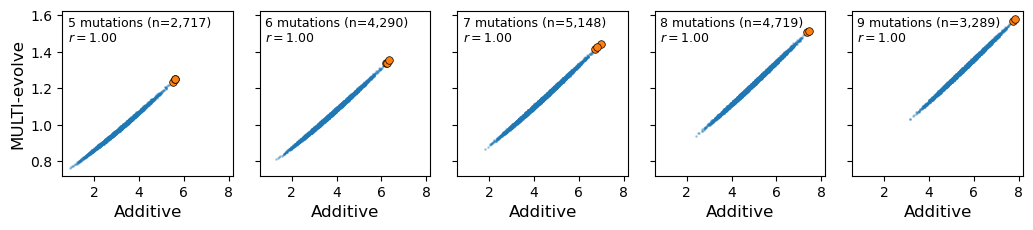

In [12]:
# Tidy figure for main.tex — (−)A134P APEX only, 5..9 mutations.
import os
from scipy.stats import pearsonr

os.makedirs('../figures', exist_ok=True)

col_add = 'prediction_additive'
col_me  = 'multievolve_pred_log2'

ns = [5, 6, 7, 8, 9]
fig, axes = plt.subplots(1, 5, figsize=(10.5, 2.4), sharex=True, sharey=True)

for j, n in enumerate(ns):
    ax = axes[j]
    sub = merged[merged['muts'].apply(len) == n]
    tran_sub = tran_merged[tran_merged['muts'].apply(len) == n]
    ax.scatter(sub[col_add], sub[col_me],
               s=1, alpha=0.3, color='C0', rasterized=True)
    if len(tran_sub) > 0:
        ax.scatter(tran_sub[col_add], tran_sub[col_me],
                   s=30, color='C1', edgecolors='black', linewidths=0.5, zorder=5)
    r, _ = pearsonr(sub[col_add], sub[col_me])
    ax.text(0.03, 0.97, f'{n} mutations (n={len(sub):,})\n$r = {r:.2f}$',
            transform=ax.transAxes, ha='left', va='top', fontsize=9)
    ax.set_xlabel('Additive', fontsize=12)

axes[0].set_ylabel('MULTI-evolve', fontsize=12)
plt.tight_layout()
fig.savefig('../figures/apex_additive_vs_multievolve_tidy.pdf', bbox_inches='tight')
plt.show()


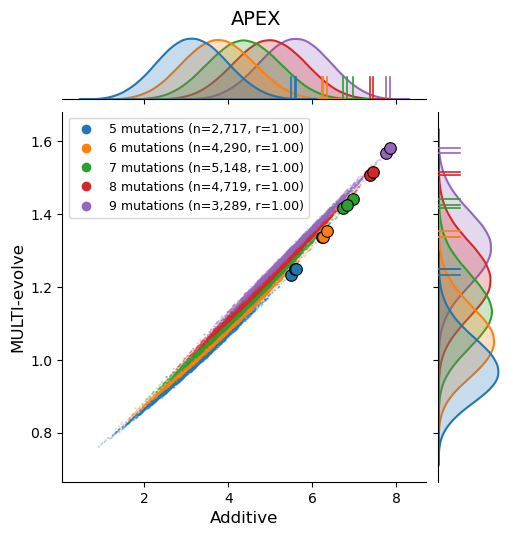

In [13]:
# Seaborn jointplot — (−)A134P APEX only.
import os
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

os.makedirs('../figures', exist_ok=True)

col_add = 'prediction_additive'
col_me  = 'multievolve_pred_log2'
ns = [5, 6, 7, 8, 9]

sub = merged[merged['muts'].apply(len).isin(ns)].copy()
sub['n_muts'] = sub['muts'].apply(len)

labels_in_order = []
palette = {}
label_map = {}
default_colors = [f'C{i}' for i in range(len(ns))]
for i, n in enumerate(ns):
    grp = sub[sub['n_muts'] == n]
    r, _ = pearsonr(grp[col_add], grp[col_me])
    label = f'{n} mutations (n={len(grp):,}, r={r:.2f})'
    labels_in_order.append(label)
    label_map[n] = label
    palette[label] = default_colors[i]
sub['group'] = sub['n_muts'].map(label_map)
sub['group'] = pd.Categorical(sub['group'], categories=labels_in_order, ordered=True)

g = sns.jointplot(
    data=sub, x=col_add, y=col_me,
    hue='group', palette=palette,
    kind='scatter',
    height=5.2, ratio=5,
    marginal_kws={'common_norm': False, 'fill': True, 'linewidth': 1.5},
    joint_kws={'s': 2, 'alpha': 0.35, 'linewidth': 0, 'rasterized': True},
    hue_order=labels_in_order,
    legend=False,
)

tran_sub = tran_merged[tran_merged['muts'].apply(len).isin(ns)].copy()
tran_sub['n_muts'] = tran_sub['muts'].apply(len)
for n in ns:
    color = palette[label_map[n]]
    tg = tran_sub[tran_sub['n_muts'] == n]
    if len(tg) == 0:
        continue
    g.ax_joint.scatter(tg[col_add], tg[col_me],
                       s=70, facecolor=color, edgecolors='black',
                       linewidths=0.8, zorder=5)
    for xv in tg[col_add]:
        g.ax_marg_x.axvline(xv, color=color, linewidth=1.2,
                            ymin=0.0, ymax=0.35, zorder=6)
    for yv in tg[col_me]:
        g.ax_marg_y.axhline(yv, color=color, linewidth=1.2,
                            xmin=0.0, xmax=0.35, zorder=6)

g.ax_joint.set_xlabel('Additive', fontsize=12)
g.ax_joint.set_ylabel('MULTI-evolve', fontsize=12)
handles = [Line2D([0], [0], marker='o', linestyle='', color=palette[l],
                  markersize=6, label=l) for l in labels_in_order]
g.ax_joint.legend(handles=handles, loc='upper left', fontsize=9, frameon=True)
g.fig.suptitle('APEX', y=1.02, fontsize=14)
g.fig.savefig('../figures/apex_additive_vs_multievolve_jointplot.pdf', bbox_inches='tight')
plt.show()


In [14]:
## Load 0-layer MULTI-evolve predictions and compute naive additive baseline
# The naive additive model takes single-mutant measurements (log2 FI) directly as
# per-mutation effects, with no regression: y_hat = sum over muts of effect[m].

# 0-layer MULTI-evolve proposals (log2-trained)
me0 = pd.read_csv('../output/apex/apex_0layer_multievolve_proposals.csv')
me0['muts_s'] = me0['Mut_string'].apply(lambda x: str(sorted(x.split('/'))))
me0 = me0[me0['num_muts'].between(5, 9)]
merged = merged.merge(
    me0[['muts_s', 'average']].rename(columns={'average': 'prediction_0layer'}),
    on='muts_s', how='left',
)
print(f'0-layer joined: {merged["prediction_0layer"].notna().sum()} rows')

# Naive additive prediction: sum of single-mutant log2 fold-change effects
single_effect = effect_dictionary['single_effect_75']
merged['prediction_additive_naive'] = merged['muts'].apply(
    lambda ms: sum(single_effect[m] for m in ms)
)
tran_merged = merged[merged['muts_s'].isin(targets)]
print(f'Paper variants after re-merge: {len(tran_merged)} / {len(targets)}')


0-layer joined: 20163 rows
Paper variants after re-merge: 13 / 13


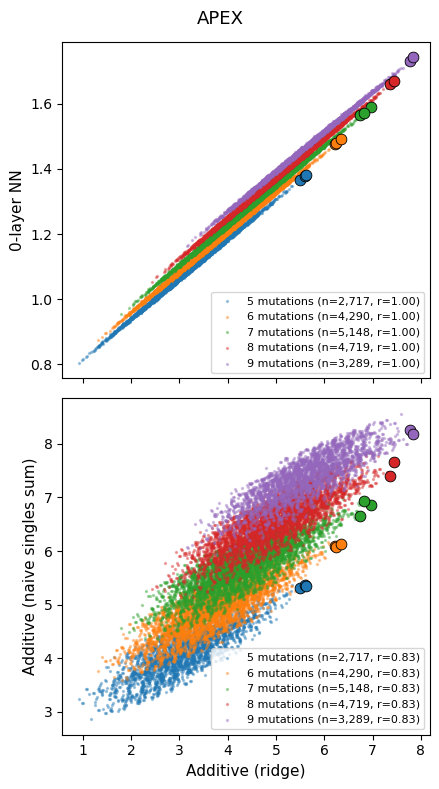

In [15]:
## Two-panel figure: 0-layer vs additive (ridge), and naive additive vs additive (ridge)
from scipy.stats import pearsonr
import os

os.makedirs('../figures', exist_ok=True)

col_ridge = 'prediction_additive'
col_0lay  = 'prediction_0layer'
col_naive = 'prediction_additive_naive'

sub       = merged[merged[col_0lay].notna()].copy()
sub['n_muts'] = sub['muts'].apply(len)
tran_sub  = tran_merged[tran_merged[col_0lay].notna()].copy()
tran_sub['n_muts'] = tran_sub['muts'].apply(len)

ns = [5, 6, 7, 8, 9]
colors = [f'C{i}' for i in range(len(ns))]

fig, axes = plt.subplots(2, 1, figsize=(4.5, 8), sharex=True)

panels = [
    (axes[0], col_ridge, col_0lay,  '', '0-layer NN'),
    (axes[1], col_ridge, col_naive, 'Additive (ridge)', 'Additive (naive singles sum)'),
]

for ax, xcol, ycol, xlab, ylab in panels:
    for i, n in enumerate(ns):
        grp   = sub[sub['n_muts'] == n]
        tgrp  = tran_sub[tran_sub['n_muts'] == n]
        if len(grp) == 0:
            continue
        r, _ = pearsonr(grp[xcol], grp[ycol])
        ax.scatter(grp[xcol], grp[ycol], s=2, alpha=0.35, color=colors[i],
                   rasterized=True,
                   label=f'{n} mutations (n={len(grp):,}, r={r:.2f})')
        if len(tgrp):
            ax.scatter(tgrp[xcol], tgrp[ycol], s=60, color=colors[i],
                       edgecolors='black', linewidths=0.6, zorder=5)
    ax.set_xlabel(xlab, fontsize=11)
    ax.set_ylabel(ylab, fontsize=11)
    ax.legend(fontsize=8, loc='lower right', frameon=True)

fig.suptitle('APEX', fontsize=13)
plt.tight_layout()
fig.savefig('../figures/apex_ridge_vs_0layer_and_naive.pdf', bbox_inches='tight')
plt.show()
